# Movie Discovery Beyond the Obvious

## Problem Definition

Can a personalized recommender help viewers discover relevant movies beyond their familiar choices while preserving recommendation quality?

This project compares a popularity baseline, a personalized model, and discovery-aware reranking of the personalized model.

Historical ratings provide evidence of preference. An unrated movie is not necessarily unseen or disliked. Novelty and diversity metrics serve as proxies for discovery, rather than proof of user satisfaction.

## Dataset

MovieLens 20M, downloaded from Kaggle, contains movie ratings, timestamps, genres, user tags, and tag-genome relevance scores. The analysis uses ratings and movie metadata; user tags and tag-genome scores are not used.

Source: [MovieLens 20M on Kaggle](https://www.kaggle.com/datasets/grouplens/movielens-20m-dataset).

In [22]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("data/raw")

# Load user ratings
ratings = pd.read_csv(
    DATA_DIR / "rating.csv",
    dtype={
        "userId": "int32",
        "movieId": "int32",
        "rating": "float32",
    },
    parse_dates=["timestamp"],
)

# Load movie titles and genres
movies = pd.read_csv(
    DATA_DIR / "movie.csv",
    dtype={"movieId": "int32"},
)

# Print data summary
print(f"No. of ratings: {len(ratings):,}")
print(f"No. of unique users: {ratings['userId'].nunique():,}")
print(f"No. of movies with ratings: {ratings['movieId'].nunique():,}")
print(f"No. of movies: {len(movies):,}")
print(f"Date range: {ratings['timestamp'].min()} to {ratings['timestamp'].max()}")
print(f"Ratings memory consumption: {ratings.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB")

display(ratings.head())
display(movies.head())

No. of ratings: 20,000,263
No. of unique users: 138,493
No. of movies with ratings: 26,744
No. of movies: 27,278
Date range: 1995-01-09 11:46:44 to 2015-03-31 06:40:02
Ratings memory consumption: 381.5 MiB


,userId,movieId,rating,timestamp
0,1,2,3.5,2005-04-02 23:53:47
1,1,29,3.5,2005-04-02 23:31:16
2,1,32,3.5,2005-04-02 23:33:39
3,1,47,3.5,2005-04-02 23:32:07
4,1,50,3.5,2005-04-02 23:29:40


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Data Quality and Temporal Coverage

In [31]:
# Summary
print("-" * 20, "Dataset summary", "-" * 20)
print(f"No. of ratings: {len(ratings):,}")
print(f"No. of unique users: {ratings['userId'].nunique():,}")
print(f"No. of movies with ratings: {ratings['movieId'].nunique():,}")
print(f"Date range: {ratings['timestamp'].min()} to {ratings['timestamp'].max()}")

-------------------- Dataset summary --------------------
No. of ratings: 20,000,263
No. of unique users: 138,493
No. of movies with ratings: 26,744
Date range: 1995-01-09 11:46:44 to 2015-03-31 06:40:02


In [35]:
# Missing Values
print("\n", "-" * 20, "Missing Values", "-" * 20)
print("\nRatings")
print(ratings.isna().sum())

print("\nMovies")
print(movies.isna().sum())

print("\n", f"Ratings without movie metadata: {(~ratings['movieId'].isin(movies['movieId'])).sum()}")


 -------------------- Missing Values --------------------

Ratings
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Movies
movieId    0
title      0
genres     0
dtype: int64

 Ratings without movie metadata: 0


In [36]:
# Duplicates
print("\n", "-" * 20, "Duplicates", "-" * 20)

print("\nUser–movie pairs:", ratings.duplicated(["userId", "movieId"]).sum())
print("Movie IDs:", movies["movieId"].duplicated().sum())


 -------------------- Duplicates --------------------

User–movie pairs: 0
Movie IDs: 0


In [39]:
print("\n", "-" * 20, "Rating Patterns", "-" * 20)

# Rating frequency
print("\nRating distribution")
print(ratings["rating"].value_counts().sort_index())

# Rating activity over time
print("\nRatings per year")
print(
    ratings.groupby(ratings["timestamp"].dt.year)
    .size()
    .rename("rating_count")
)

# Ratings per user
print("\nRatings per user")
print(
    ratings.groupby("userId").size()
    .describe(percentiles=[0.1, 0.5, 0.9, 0.99])
)


 -------------------- Rating Patterns --------------------

Rating distribution
rating
0.5     239125
1.0     680732
1.5     279252
2.0    1430997
2.5     883398
3.0    4291193
3.5    2200156
4.0    5561926
4.5    1534824
5.0    2898660
Name: count, dtype: int64

Ratings per year
timestamp
1995          4
1996    1612609
1997     700982
1998     308070
1999    1198384
2000    1953659
2001    1186125
2002     869719
2003    1035878
2004    1170049
2005    1803158
2006    1171836
2007    1053430
2008    1158777
2009     930036
2010     903691
2011     766366
2012     731389
2013     599327
2014     562888
2015     283886
Name: rating_count, dtype: int64

Ratings per user
count    138493.000000
mean        144.413530
std         230.267257
min          20.000000
10%          24.000000
50%          68.000000
90%         334.000000
99%        1113.080000
max        9254.000000
dtype: float64


## Temporal Evaluation Design

The dataset is split into training, validation and testing based on timeline. Ratings before January 1, 2013 are used for training. Ratings between January 1, 2013 and Dec 31, 2013 are used for validation. Ratings from Jan 1, 2014 through March 31, 2015 are used for testing. Chronological separation evaluates later recorded preferences using earlier information. 

The recommender uses only information available before January 1, 2013. Its learned preferences, movie popularity counts, eligible movie catalog, and user rating histories remain unchanged during validation and testing. Ratings from 2013 help select the reranking setting but are not used to update the model or user profiles. The experiment therefore measures how well fixed recommendations match preferences recorded over subsequent years; a live service would incorporate new ratings and movies over time.

The primary evaluation includes users with at least 20 training ratings and movies appearing in training. Ranking metrics are computed only for users with at least one eligible held-out positive rating, defined as a rating of 4.0 or higher.

These restrictions retain 25.47% of validation rating records and 14.88% of test rating records before the positive-rating filter. Final ranking evaluation includes 3,504 validation users and 2,718 test users. Results therefore apply to an established-user, established-item cohort, not the entire platform population.

New users and new movies are excluded from the primary experiment. A popularity fallback for new users is a proposed extension and has not been separately evaluated.

In [40]:
TRAIN_END = pd.Timestamp("2013-01-01")
VALIDATION_END = pd.Timestamp("2014-01-01")

# Split dataset into train, validation, test
train = ratings.loc[ratings["timestamp"] < TRAIN_END].copy()
validation = ratings.loc[(ratings["timestamp"] >= TRAIN_END) & (ratings["timestamp"] < VALIDATION_END)].copy()
test = ratings.loc[ratings["timestamp"] >= VALIDATION_END].copy()

train_history_counts = train.groupby("userId").size()
train_movie_ids = pd.Index(train["movieId"].unique())

# Summarize each partition's size, date range, and coverage by training histories and movies. 
# Count rating rows from users with no training history, movies absent from training, 
# and user–movie pairs where the user has at least 20 training ratings and the movie is known.
# These are diagnostic counts; no rows are filtered or modified.

summary_rows = []

for name, dataset in (
    ("Training", train),
    ("Validation", validation),
    ("Test", test),
):
    history_counts = (dataset["userId"].map(train_history_counts).fillna(0))
    known_movie = dataset["movieId"].isin(train_movie_ids)

    summary_rows.append({
        "partition": name,
        "ratings": len(frame),
        "users": dataset["userId"].nunique(),
        "movies": dataset["movieId"].nunique(),
        "start": dataset["timestamp"].min(),
        "end": dataset["timestamp"].max(),
        "ratings_from_users_without_training_history": int(history_counts.eq(0).sum()),
        "ratings_for_movies_absent_from_training": int((~known_movie).sum()),
        "ratings_with_20plus_history_and_known_movie": int((history_counts.ge(20) & known_movie).sum()),
    })

display(pd.DataFrame(summary_rows).set_index("partition"))

,ratings,users,movies,start,end,ratings_from_users_without_training_history,ratings_for_movies_absent_from_training,ratings_with_20plus_history_and_known_movie
partition,,,,,,,,
Training,2718,128722,19551,1995-01-09 11:46:44,2012-12-31 23:59:35,0,0,18551911
Validation,2718,8129,16102,2013-01-01 00:00:10,2013-12-31 23:59:59,417734,24465,152673
Test,2718,9148,20380,2014-01-01 00:00:04,2015-03-31 06:40:02,657067,106794,125976


In [41]:
# A Rating of 4 or more is considered as a positive movie rating
POSITIVE_THRESHOLD = 4.0

# Consider users with at least 20 movie ratings in the training set
MIN_HISTORY = 20

eligible_user_ids = train_history_counts[train_history_counts >= MIN_HISTORY].index

evaluation_rows = []

for name, dataset in (
    ("Validation", validation),
    ("Test", test),
):
    eligible = dataset.loc[dataset["userId"].isin(eligible_user_ids) & dataset["movieId"].isin(train_movie_ids)]

    positive_counts = (
        eligible.loc[eligible["rating"] >= POSITIVE_THRESHOLD]
        .groupby("userId")
        .size()
    )

    evaluation_rows.append({
        "partition": name,
        "eligible_ratings": len(eligible),
        "eligible_users": eligible["userId"].nunique(),
        "positive_ratings": int(positive_counts.sum()),
        "users_with_1plus_positive": int(positive_counts.ge(1).sum()),
        "users_with_5plus_positives": int(positive_counts.ge(5).sum()),
        "rating_coverage_pct": round(100 * len(eligible) / len(frame), 2),
    })

display(pd.DataFrame(evaluation_rows).set_index("partition"))

,eligible_ratings,eligible_users,positive_ratings,users_with_1plus_positive,users_with_5plus_positives,rating_coverage_pct
partition,,,,,,
Validation,152673,3648,67987,3504,2496,5617.11
Test,125976,2865,52407,2718,1931,4634.88


### Evaluation Cohort

A rating of 4.0 or higher is treated as evidence of positive preference. Eligible users must have at least 20 training ratings, including both
positive and lower ratings. Held-out ratings are further restricted to movies present in the training catalog.

These restrictions retain 152,673 validation ratings (25.47%) and 125,976 test ratings (14.88%). Among eligible users, 3,504 validation
users and 2,718 test users have at least one held-out positive rating and enter the ranking evaluation.

Counts of users with five or more positives are diagnostic only; five positives are not required for inclusion. This evaluation focuses on established users and known movies, so its results do not represent cold-start users or the full dataset population.

In [5]:
# Build a popularity baseline using training ratings only.
# Count each movie's total and positive ratings (>= 4.0), then rank by positive count, breaking ties by total count and movie ID.
# Average ratings are included for inspection, not ranking.
# Join titles and genres to display the top 15 movies.

movie_stats = (
    train.groupby("movieId")
    .agg(
        rating_count=("rating", "size"),
        mean_rating=("rating", "mean"),
    )
)

positive_counts = (
    train.loc[train["rating"] >= POSITIVE_THRESHOLD]
    .groupby("movieId")
    .size()
)

movie_stats["positive_count"] = (
    positive_counts.reindex(movie_stats.index, fill_value=0)
)

popularity_ranking = (
    movie_stats.reset_index()
    .sort_values(
        ["positive_count", "rating_count", "movieId"],
        ascending=[False, False, True],
    )
)

display(
    popularity_ranking.head(15).merge(
        movies,
        on="movieId",
        how="left",
        validate="one_to_one",
    )[
        [
            "movieId",
            "title",
            "genres",
            "positive_count",
            "rating_count",
            "mean_rating",
        ]
    ]
)

,movieId,title,genres,positive_count,rating_count,mean_rating
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,50697,57390,4.453441
1,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,48783,62794,4.171505
2,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,46978,59177,4.183500
3,356,Forrest Gump (1994),Comedy|Drama|Romance|War,44311,62091,4.024230
4,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,39836,50759,4.200408
5,527,Schindler's List (1993),Drama|War,38210,45849,4.329745
6,110,Braveheart (1995),Action|Drama|War,36743,51120,4.053071
7,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,36639,43197,4.346159
8,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,35765,45601,4.192605
9,457,"Fugitive, The (1993)",Thriller,34344,48208,3.989161


### Model Selection: TruncatedSVD

Singular Value Decomposition (SVD) identifies underlying patterns in a user–movie interaction matrix. Users form the rows, movies
form the columns, and ratings of 4.0 or higher are represented as positive interactions.

TruncatedSVD retains 64 latent factors: numerical patterns learned from overlapping user preferences, rather than predefined genres.
Each user and movie receives a representation in this shared factor space. Combining their representations produces a score used to rank movies for that user.

TruncatedSVD was selected because it handles sparse matrices efficiently and provides a manageable collaborative-filtering model for testing whether personalization improves on popularity. It can identify preference relationships without requiring movie descriptions or demographic information.

This initial modeling choice does not establish SVD as the best recommendation algorithm. Its scores are not probabilities. In this implementation, missing interactions and ratings below 4.0 are both encoded as zeros, and SVD includes those zeros in its matrix approximation. This limits its ability to distinguish missing preference information from lower-rated interactions.

## Popularity Baseline and Ranking Evaluation

The baseline ranks training-catalog movies by the number of ratings of 4.0 or higher. Ties are resolved by total training rating count, then movie ID. Each user's previously rated movies are excluded. This provides a non-personalized reference for assessing whether learned preferences improve recommendations.

For each user, the starting candidate pool contains movies that appeared in training and that the user did not rate during training. Popularity and SVD each rank this entire pool and recommend ten movies. The discovery-aware method takes SVD's top 100 movies, then selects
and reorders ten of them to balance relevance and genre diversity.

To evaluate the recommendations, a movie counts as relevant if the user rated it 4.0 or higher in the held-out evaluation period.
All other recommended movies receive no relevance credit, although an unrated movie may still be enjoyable. “Binary relevance” means
each movie receives either 1 (observed positive rating) or 0 (no observed positive rating).

### Recall@10

Recall@10 is the number of observed positive movies appearing in the top ten recommendations divided by the user's total eligible held-out positive movies. It measures recovery of recorded future preferences.

### NDCG@10

NDCG@10 rewards relevant movies more strongly near the top of the list. A relevant movie at rank r contributes 1 / log2(r + 1). The sum is divided by the ideal score obtained by placing the user's eligible positive movies first, up to ten positions.

Recall@10 measures recovery, while NDCG@10 measures ranking quality. Both are averaged equally across users with at least one eligible held-out positive rating.

### Interpretation Limits

Unrated candidates have unknown relevance but receive no relevance credit in this offline evaluation. Consequently, a recommendation may be enjoyable without counting as a hit. These metrics evaluate recovery of observed preferences, not complete viewer satisfaction.

Users with no eligible held-out positive ratings are excluded because recall and normalized ranking quality are undefined for this protocol. Results are conditional on this evaluation cohort.

In [6]:
import numpy as np

# Generate and evaluate popularity-based recommendations. Called first with validation ratings, then with test ratings.
# For each eligible user with at least one eligible positive evaluation rating, exclude all training-rated movies 
# and select the top k remaining movies from the supplied training-only popularity ranking.
# Compare recommendations with evaluation movies rated >= positive_threshold that belong to the candidate catalog, 
# then calculate Recall@k and NDCG@k. Return per-user recommendations, positive counts, and metric scores.
# This function does not train a model or update the supplied ranking.

def evaluate_popularity(
    training_ratings,
    evaluation_ratings,
    ranked_movie_ids,
    eligible_users,
    positive_threshold=4.0,
    k=10,
):
    """Evaluate popularity recommendations against observed positives.

    Parameters
    ----------
    training_ratings : pandas.DataFrame
        Historical ratings containing userId and movieId.
    evaluation_ratings : pandas.DataFrame
        Held-out ratings containing userId, movieId, and rating.
    ranked_movie_ids : sequence of int
        Candidate movie IDs ordered by training-only popularity.
    eligible_users : sequence of int
        Users permitted in the evaluation cohort.
    positive_threshold : float
        Minimum held-out rating considered positive.
    k : int
        Number of recommendations per user.

    Returns
    -------
    pandas.DataFrame
        Per-user Recall@k, NDCG@k, and recommendation lists.
        Includes only users with at least one eligible positive.
    """
    if k < 1:
        raise ValueError("k must be at least 1.")

    candidate_ids = set(ranked_movie_ids)

    seen_by_user = (
        training_ratings.loc[
            training_ratings["userId"].isin(eligible_users)
        ]
        .groupby("userId")["movieId"]
        .agg(set)
        .to_dict()
    )

    positives_by_user = (
        evaluation_ratings.loc[
            evaluation_ratings["userId"].isin(eligible_users)
            & evaluation_ratings["movieId"].isin(candidate_ids)
            & (
                evaluation_ratings["rating"]
                >= positive_threshold
            )
        ]
        .groupby("userId")["movieId"]
        .agg(set)
        .to_dict()
    )

    discounts = 1 / np.log2(np.arange(2, k + 2))
    rows = []

    for user_id, positive_ids in positives_by_user.items():
        seen = seen_by_user.get(user_id, set())
        relevant = positive_ids - seen

        if not relevant:
            continue

        recommendations = []
        for movie_id in ranked_movie_ids:
            if movie_id not in seen:
                recommendations.append(movie_id)
                if len(recommendations) == k:
                    break

        hits = np.array(
            [movie_id in relevant for movie_id in recommendations],
            dtype=float,
        )

        dcg = float(
            np.sum(hits * discounts[:len(recommendations)])
        )
        ideal_dcg = float(
            discounts[:min(k, len(relevant))].sum()
        )

        rows.append({
            "userId": user_id,
            "positive_count": len(relevant),
            f"recall@{k}": float(hits.sum() / len(relevant)),
            f"ndcg@{k}": dcg / ideal_dcg,
            "recommendations": recommendations,
        })

    return pd.DataFrame(rows)



popularity_validation = evaluate_popularity(
    training_ratings=train,
    evaluation_ratings=validation,
    ranked_movie_ids=popularity_ranking["movieId"].tolist(),
    eligible_users=eligible_user_ids,
    positive_threshold=POSITIVE_THRESHOLD,
    k=10,
)

print(f"Evaluated users: {len(popularity_validation):,}")
display(
    popularity_validation[["recall@10", "ndcg@10"]]
    .mean()
    .to_frame("popularity_baseline")
)

Evaluated users: 3,504


,popularity_baseline
recall@10,0.026693
ndcg@10,0.059778


## Personalized Modeling with TruncatedSVD

TruncatedSVD learns patterns from the training user–movie interaction matrix, where each row represents a user and each column represents a movie. It identifies shared preferences: users who like overlapping movies can help reveal other movies that may interest one another. These learned patterns are called latent factors because they emerge from the interactions rather than being supplied as predefined categories such as genres.

The model is unsupervised: it learns a representation of the training matrix without being given target recommendation scores. Its recommendations are subsequently evaluated against positive ratings in the validation or test dataset. These later ratings are held out, meaning they are excluded from model training.

**Representing preferences**

Each training rating of 4.0 or higher is converted to 1, indicating a positive interaction. Every other matrix entry is 0, including both lower ratings and movies the user has not rated.

This representation focuses on which movies users liked, but loses some information:
- Ratings of 4.0 and 5.0 carry the same weight.
- Lower ratings and missing ratings receive the same value.
- A missing rating does not establish that a user dislikes—or has never watched—the movie.

Although zeros are not explicitly defined as dislikes, ordinary SVD includes them when approximating the matrix. It therefore does not treat missing entries as unknown values to be ignored.

**Building the interaction matrix**

The training matrix contains 128,722 users, 19,551 movies, and 9,254,778 positive interactions. Most entries are zero, so it is stored as a sparse matrix, which stores the nonzero values and their positions instead of allocating space for every user–movie combination.
User and movie IDs are mapped to matrix row and column positions using training data only. This keeps validation and test interactions out of the model-building process.

**Learning user and movie representations**

TruncatedSVD compresses the matrix into 64 latent factors. Each user and movie receives a numerical representation in this shared factor space. Combining a user's representation with each movie's representation produces scores that can be used to rank candidate movies.

TruncatedSVD was selected because it works efficiently with sparse matrices and provides a manageable starting point for testing whether personalization improves on popularity. The configuration uses 64 components, seven randomized-SVD iterations, and random_state=42. The iterations help refine the approximation, while the fixed random seed supports reproducibility. The component count is an initial design choice rather than the outcome of an extensive hyperparameter search.

**Producing recommendations**

Recommendation scores represent the model's reconstructed interaction strengths. A higher score places a movie higher in a user's recommendation ranking; it does not represent a predicted star rating or a calibrated probability that the user will enjoy the movie.

Before selecting recommendations, every movie the user rated during training is excluded, regardless of whether that rating was positive or negative. This directs recommendations toward movies absent from the user's recorded training history.

**Assessing performance**
No feature scaling is applied because the matrix uses a common binary representation. Tags and tag-genome scores are excluded from the model. Genres are used separately for discovery-aware reranking and evaluation.

The explained variance ratio describes how much variation in the training matrix the retained factors capture. It does not establish recommendation quality. That quality is assessed using Recall@10 and NDCG@10, which compare recommendations with positive ratings in the validation or test dataset.

In [7]:
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD

# Stable mappings based exclusively on training data.
model_user_ids = np.sort(train["userId"].unique())
model_movie_ids = np.sort(train["movieId"].unique())

user_index = pd.Index(model_user_ids)
movie_index = pd.Index(model_movie_ids)

positive_train = train.loc[train["rating"] >= POSITIVE_THRESHOLD, ["userId", "movieId"]]

interaction_matrix = csr_matrix(
    (
        np.ones(len(positive_train), dtype=np.float32),
        (
            user_index.get_indexer(positive_train["userId"]),
            movie_index.get_indexer(positive_train["movieId"]),
        ),
    ),
    shape=(len(model_user_ids), len(model_movie_ids)),
    dtype=np.float32,
)

# The model uses 64 components and seven randomized-SVD refinement iterations as fixed initial settings.
# These values provide a computationally manageable starting configuration but were not selected through hyperparameter tuning.

svd_model = TruncatedSVD(
    n_components=64,
    n_iter=7,
    random_state=42,
)

user_factors = svd_model.fit_transform(interaction_matrix)
movie_factors = svd_model.components_.T

print("Interaction matrix:", interaction_matrix.shape)
print(f"Positive interactions: {interaction_matrix.nnz:,}")
print("User factors:", user_factors.shape)
print("Movie factors:", movie_factors.shape)
print(
    "Explained variance ratio:",
    round(float(svd_model.explained_variance_ratio_.sum()), 4),
)

Interaction matrix: (128722, 19551)
Positive interactions: 9,254,778
User factors: (128722, 64)
Movie factors: (19551, 64)
Explained variance ratio: 0.3245


### Interpreting the SVD Output

The training interaction matrix contains **128,722 users** and **19,551 movies**. Its **9,254,778 nonzero entries** represent ratings of 4.0 or higher. All remaining entries are zero, including lower ratings and missing interactions.

After fitting TruncatedSVD, each user and movie is represented by **64 learned factor values**. The user-factor matrix therefore has shape `(128722, 64)`, and the movie-factor matrix has shape `(19551, 64)`. These representations will be combined to calculate personalized ranking scores.

The 64 components capture approximately **32.45% of the variance in the training interaction matrix**. This describes the compressed representation; it does not measure recommendation accuracy or the percentage of recommendations that are correct. Recommendation quality is assessed separately using validation and test ranking metrics.

The model uses **64 components** and **seven randomized-SVD refinement iterations** as fixed initial settings, rather than values selected through hyperparameter tuning. The fixed random seed (`random_state=42`) supports reproducibility.

At this stage, the model has been fitted, but recommendations have not yet been generated or evaluated.

In [8]:
validation_user_ids = popularity_validation["userId"].to_numpy()

# Build exclusion lists for the validation cohort.
seen_indices_by_user = {
    user_id: movie_index.get_indexer(group["movieId"].to_numpy())
    for user_id, group in (
        train.loc[train["userId"].isin(validation_user_ids)]
        .groupby("userId", sort=False)
    )
}

discounts = 1 / np.log2(np.arange(2, 12))
svd_rows = []

# Reuse the baseline's relevance sets and evaluation cohort.
positive_ids_by_user = (
    validation.loc[
        validation["userId"].isin(validation_user_ids)
        & validation["movieId"].isin(model_movie_ids)
        & (validation["rating"] >= POSITIVE_THRESHOLD)
    ]
    .groupby("userId")["movieId"]
    .agg(set)
    .to_dict()
)

for user_id in validation_user_ids:
    user_position = user_index.get_loc(user_id)
    seen_positions = seen_indices_by_user[user_id]
    seen_ids = set(model_movie_ids[seen_positions])

    relevant = positive_ids_by_user[user_id] - seen_ids

    # Scores are reconstructed interaction strengths, not probabilities.
    scores = movie_factors @ user_factors[user_position]
    scores[seen_positions] = -np.inf

    # Movie ID provides a deterministic tie-break.
    top_positions = np.lexsort((model_movie_ids, -scores))[:10]
    recommendations = model_movie_ids[top_positions].tolist()

    hits = np.array(
        [movie_id in relevant for movie_id in recommendations],
        dtype=float,
    )

    dcg = float(np.sum(hits * discounts))
    ideal_dcg = float(discounts[:min(10, len(relevant))].sum())

    svd_rows.append({
        "userId": user_id,
        "positive_count": len(relevant),
        "recall@10": float(hits.sum() / len(relevant)),
        "ndcg@10": dcg / ideal_dcg,
        "recommendations": recommendations,
    })

svd_validation = pd.DataFrame(svd_rows)

comparison = pd.DataFrame({
    "Popularity": popularity_validation[
        ["recall@10", "ndcg@10"]
    ].mean(),
    "SVD": svd_validation[
        ["recall@10", "ndcg@10"]
    ].mean(),
})

comparison["relative_change_pct"] = (
    100 * (comparison["SVD"] / comparison["Popularity"] - 1)
)

print(f"Evaluated users: {len(svd_validation):,}")
display(comparison)

Evaluated users: 3,504


,Popularity,SVD,relative_change_pct
recall@10,0.026693,0.042186,58.044121
ndcg@10,0.059778,0.093522,56.448229


### Validation Results: Personalization vs. Popularity

Both models are evaluated on the same **3,504 users**, using the same training-catalog movies and positive validation ratings. Movies previously rated during training are excluded from each user's recommendations.

| Metric | Popularity | SVD | Relative improvement |
|---|---:|---:|---:|
| Recall@10 | 0.026693 | 0.042186 | 58.04% |
| NDCG@10 | 0.059778 | 0.093522 | 56.45% |

**Recall@10** measures the proportion of a user's eligible positive validation movies retrieved in the top ten recommendations. **NDCG@10** also accounts for their positions, awarding more credit when relevant movies appear near the top. Both results are averaged across users, giving each user equal weight.

SVD improves both metrics over the popularity baseline. These validation results support the value of learning individual preference patterns rather than recommending the same popularity-ranked movies to everyone.

The relative improvements describe gains over the baseline; they are not percentage-point increases or measures of user satisfaction. Evaluation uses observed positive ratings, so a recommendation without a matching positive validation rating receives no credit even though the user might enjoy it.

These results assess relevance. The next analysis examines whether personalization also changes recommendation diversity, popularity-based novelty, and catalog coverage.

## Discovery Metrics

Recommendation relevance measures whether suggested movies match observed positive ratings. Discovery metrics examine additional properties: variety within a recommendation list, how frequently the movies were rated, the breadth of the catalog recommended, and differences from a user's past preferences.

Discovery is assessed through four complementary proxies. None directly establishes that a viewer finds a recommendation surprising, enjoyable, or unfamiliar.

### Within-List Genre Diversity

This metric measures how different the recommended movies are from one another based on their genre labels.

For each pair of movies, **Jaccard similarity** is the number of shared genres divided by the number of distinct genres in their combined sets. Genre distance is **1 minus this similarity**.

For example:

- Movie A: `{Action, Adventure}`
- Movie B: `{Action, Thriller}`
- Shared genres: `{Action}` — one genre.
- Combined genres: `{Action, Adventure, Thriller}` — three genres.

Their similarity is `1 / 3`, so their distance is approximately **0.667**.

Identical genre sets have a distance of **0**, while sets with no shared genres have a distance of **1**. A ten-movie list contains 45 unique pairs. Distances are averaged across those pairs to obtain the list's diversity score, then equally across users.

Higher values indicate greater genre variety within a list. They do not establish that the genres are new to the user.

### Popularity Novelty

This metric measures how uncommon a recommended movie is based on training rating activity:

`novelty = -log2(training rating count / number of training users)`

Because duplicate user–movie pairs are absent, the ratio represents the fraction of training users who rated the movie. The count includes all training ratings, regardless of whether they were positive.

For example:

| Fraction of training users who rated the movie | Novelty score |
|---|---:|
| 50% | 1 bit |
| 25% | 2 bits |
| 12.5% | 3 bits |

Each halving of the fraction adds one bit. Higher scores therefore indicate less frequently rated movies. Scores are averaged within recommendation lists and then equally across users.

This measures rarity in the dataset, not personal unfamiliarity. A rarely rated movie may already be familiar to a viewer, and rating frequency is not a direct measure of real-world popularity.

### Catalog Coverage

This metric measures how broadly the recommender draws from the available catalog:

`coverage = distinct recommended movies / training-catalog size`

For example, if recommendations across all evaluated users contain **500 distinct movies** from a catalog of **20,000 movies**, coverage is **2.5%**.

A movie recommended to many users counts only once. Coverage therefore distinguishes a system that repeatedly recommends a small set of movies from one that distributes recommendations across a broader selection.

Unlike the other metrics, coverage is calculated across the entire evaluation cohort rather than averaged per user. It depends on cohort size and composition, so validation and test coverage are not directly comparable.

### Distance from Positive Training History

This metric measures how different each recommendation's genre combination is from those of movies the user positively rated during training.

Each recommended movie is compared with every genre combination in that positive history. Its **highest Jaccard similarity** identifies the closest match. Distance is **1 minus that highest similarity**.

For example, suppose a user's positive history contains:

- `{Action, Adventure}`
- `{Crime, Thriller}`

A recommendation with genres `{Action, Sci-Fi}` has similarities of **1/3** and **0**, respectively. Its closest match has similarity **1/3**, giving a history distance of approximately **0.667**.

A recommendation with an identical genre set to a previously liked movie has distance **0**. A recommendation sharing no genres with any positively rated training movie has distance **1**.

Distances are averaged within each recommendation list and then equally across users with usable positive genre history. Higher values indicate greater distance from previously liked genre combinations.

This differs from within-list diversity: a list can contain varied movies that all closely resemble the user's history, or similar movies that all differ from that history.

### Interpretation and Limits

Higher diversity, novelty, coverage, or history distance is not automatically better. Recommendations must also remain relevant. These metrics describe different aspects of discovery and should be interpreted alongside Recall@10 and NDCG@10.

Genre labels are broad and do not capture themes, tone, style, or actual viewing history. Movies without recorded ratings may already have been watched. Consequently, these measures do not establish actual surprise, enjoyment, or satisfaction.

Movies with missing genre labels are excluded from genre-distance calculations. The percentage of recommendation lists affected is reported; no evaluated list was affected in these experiments.

In [42]:
from itertools import combinations

genre_sets = {
    row.movieId: set(row.genres.split("|"))
    - {"(no genres listed)"}
    for row in movies.itertuples(index=False)
}

novelty_by_movie = -np.log2(
    movie_stats["rating_count"] / len(model_user_ids)
)


def summarize_discovery(results, genre_lookup, novelty_lookup,
                        catalog_size):
    """Summarize discovery proxies for recommendation lists.

    Parameters
    ----------
    results : pandas.DataFrame
        Per-user results with a recommendations column.
    genre_lookup : dict
        Mapping from movie IDs to genre sets.
    novelty_lookup : pandas.Series
        Training-only popularity novelty indexed by movie ID.
    catalog_size : int
        Number of candidate movies in the training catalog.

    Returns
    -------
    pandas.Series
        Mean genre diversity, mean popularity novelty, catalog
        coverage, and fraction of lists containing missing genres.
    """
    diversities = []
    novelties = []
    recommended_ids = set()
    missing_genre_lists = 0

    for recommendations in results["recommendations"]:
        recommended_ids.update(recommendations)
        
        novelties.append(float(novelty_lookup.loc[recommendations].mean()))

        genres = [
            genre_lookup.get(movie_id, set())
            for movie_id in recommendations
        ]
        
        missing_genre_lists += int(any(not g for g in genres))

        distances = [
            1 - len(left & right) / len(left | right)
            for left, right in combinations(genres, 2)
            if left and right
        ]
        diversities.append(
            float(np.mean(distances)) if distances else np.nan
        )

    return pd.Series({
        "genre_diversity": float(np.nanmean(diversities)),
        "popularity_novelty_bits": float(np.mean(novelties)),
        "catalog_coverage_pct":
            100 * len(recommended_ids) / catalog_size,
        "lists_with_missing_genres_pct":
            100 * missing_genre_lists / len(results),
    })


discovery_comparison = pd.DataFrame({
    "Popularity": summarize_discovery(
        popularity_validation,
        genre_sets,
        novelty_by_movie,
        len(model_movie_ids),
    ),
    "SVD": summarize_discovery(
        svd_validation,
        genre_sets,
        novelty_by_movie,
        len(model_movie_ids),
    ),
})

display(discovery_comparison)

,Popularity,SVD
genre_diversity,0.803423,0.788297
popularity_novelty_bits,1.720534,3.174309
catalog_coverage_pct,1.391233,4.705642
lists_with_missing_genres_pct,0.000000,0.000000


In [10]:
CANDIDATE_POOL_SIZE = 100

svd_candidate_cache = {}

for user_id in validation_user_ids:
    user_position = user_index.get_loc(user_id)

    scores = movie_factors @ user_factors[user_position]
    scores[seen_indices_by_user[user_id]] = -np.inf

    ranked_positions = np.lexsort((model_movie_ids, -scores))
    ranked_positions = ranked_positions[np.isfinite(scores[ranked_positions])][:CANDIDATE_POOL_SIZE]

    svd_candidate_cache[user_id] = {
        "movie_ids": model_movie_ids[ranked_positions].copy(),
        "scores": scores[ranked_positions].copy(),
    }

print(f"Cached users: {len(svd_candidate_cache):,}")
print(
    "Candidate counts:",
    pd.Series([
        len(entry["movie_ids"])
        for entry in svd_candidate_cache.values()
    ]).describe().to_dict(),
)

# Confirm caching preserves the recommendations already evaluated.
assert all(
    svd_candidate_cache[row.userId]["movie_ids"][:10].tolist() == row.recommendations
    for row in svd_validation.itertuples(index=False)
)

print("Top-10 consistency check passed.")

Cached users: 3,504
Candidate counts: {'count': 3504.0, 'mean': 100.0, 'std': 0.0, 'min': 100.0, '25%': 100.0, '50%': 100.0, '75%': 100.0, 'max': 100.0}
Top-10 consistency check passed.


## Discovery-Aware Reranking

The reranker selects **ten movies from each user's top 100 SVD candidates**. SVD provides a personalized shortlist; reranking then balances the model's relevance scores with genre variety within the final list.

For example, SVD might rank several action thrillers near the top. The reranker can include a slightly lower-ranked comedy or animated movie if its relevance score is sufficiently strong and it adds variety.

The model is not retrained. Reranking changes which candidates are selected and their order, using the existing SVD scores and movie genres.

### Normalizing Relevance Scores

SVD scores are **min–max normalized separately within each user's candidate pool**:

`normalized_relevance = (score − minimum_score) / (maximum_score − minimum_score)`

The highest-scoring candidate receives 1, and the lowest receives 0. This preserves the original score ordering while placing relevance on a scale comparable to genre similarity.

For example, suppose the candidate scores range from 0.2 to 0.8:

| Original SVD score | Normalized relevance |
|---|---:|
| 0.8 | 1.0 |
| 0.5 | 0.5 |
| 0.2 | 0.0 |

A normalized score of 0 does not mean a movie is irrelevant: it means the movie has the lowest score within this top-100 shortlist. These values are not probabilities. If all candidate scores are equal, the implementation assigns all candidates a normalized relevance of 1.

### Selecting Movies One at a Time

The reranker uses a **greedy selection procedure**. It selects one movie, updates the genre similarities of the remaining candidates, and repeats until ten movies have been selected.

At each step, the selected movie maximizes:

`selection_score = relevance_weight × normalized_relevance
                   − (1 − relevance_weight) × maximum_genre_similarity`

**Maximum genre similarity** is the highest Jaccard similarity between the candidate and any movie already selected. A candidate that closely resembles even one selected movie receives a larger penalty.

For the first selection, the list is empty, so the similarity penalty is zero. For the positive weights tested here, the highest-ranked SVD candidate is selected first. Ties favor the original SVD ordering.

### Example: Balancing Relevance and Variety

Suppose an action thriller has already been selected. Two remaining candidates have these values:

| Candidate | Normalized relevance | Maximum similarity to selected movies |
|---|---:|---:|
| Another action thriller | 0.90 | 1.00 |
| A comedy | 0.80 | 0.00 |

With `relevance_weight = 0.8`:

- Action thriller: `0.8 × 0.90 − 0.2 × 1.00 = 0.52`
- Comedy: `0.8 × 0.80 − 0.2 × 0.00 = 0.64`

The comedy is selected because its contribution to variety outweighs the difference in relevance.

After each selection, similarities are updated. If the comedy is selected, another comedy may now receive a larger penalty. The procedure therefore responds to the list as it develops.

Greedy selection chooses the best available candidate at each step; it does not guarantee the best possible ten-movie combination.

### Comparing Relevance Weights

Four weights are compared using validation data:

| Relevance weight | Relevance coefficient | Similarity-penalty coefficient |
|---|---:|---:|
| 1.0 | 1.0 | 0.0 |
| 0.9 | 0.9 | 0.1 |
| 0.8 | 0.8 | 0.2 |
| 0.7 | 0.7 | 0.3 |

A weight of **1.0 preserves the original SVD ordering**. Lower weights give genre similarity a stronger influence on selection.

The weight controls the scoring tradeoff. A value of 0.8 does **not** mean that 80% of recommendation quality is retained or that a viewer has an 80% probability of enjoying a movie. The actual effects are assessed through validation relevance and discovery metrics.

### What the Reranker Optimizes

The objective directly encourages **within-list genre variety** by penalizing similarity to already selected movies. It does not explicitly reward less-popular movies or differences from the user's positive training history.

Popularity novelty, catalog coverage, and distance from historical preferences are therefore measured outcomes. They may increase, decrease, or remain similar after reranking.

Selection is also limited to the top 100 SVD candidates. A movie outside that pool cannot enter the final list, even if it would add substantial variety.

In [11]:
def rerank_candidates(movie_ids, scores, genre_lookup,
                      relevance_weight=0.9, k=10):
    """Select recommendations balancing relevance and genre diversity.

    Parameters
    ----------
    movie_ids : numpy.ndarray
        Candidate IDs ordered by descending relevance.
    scores : numpy.ndarray
        SVD scores aligned with movie_ids.
    genre_lookup : dict
        Mapping from movie IDs to genre sets.
    relevance_weight : float
        Weight between 0 and 1; 1 preserves relevance ordering.
    k : int
        Maximum number of recommendations.

    Returns
    -------
    list of int
        Selected movie IDs in recommendation order.
    """
    if not 0 <= relevance_weight <= 1:
        raise ValueError("relevance_weight must be between 0 and 1.")
    if k < 1:
        raise ValueError("k must be at least 1.")
    if len(movie_ids) != len(scores):
        raise ValueError("movie_ids and scores must have equal lengths.")
    if len(movie_ids) == 0:
        return []
    if not np.isfinite(scores).all():
        raise ValueError("Candidate scores must be finite.")

    if relevance_weight == 1:
        return movie_ids[:k].tolist()

    score_range = float(np.max(scores) - np.min(scores))
    normalized = (
        (scores - np.min(scores)) / score_range
        if score_range > 0
        else np.ones(len(scores))
    )

    genres = [genre_lookup.get(mid, set()) for mid in movie_ids]
    available = np.ones(len(movie_ids), dtype=bool)
    max_similarity = np.zeros(len(movie_ids), dtype=float)
    selected = []

    for _ in range(min(k, len(movie_ids))):
        objective = (
            relevance_weight * normalized
            - (1 - relevance_weight) * max_similarity
        )
        objective[~available] = -np.inf

        # Candidate ordering breaks ties in favor of SVD relevance.
        chosen = int(np.argmax(objective))
        selected.append(int(movie_ids[chosen]))
        available[chosen] = False

        chosen_genres = genres[chosen]
        for position, candidate_genres in enumerate(genres):
            if available[position]:
                union = chosen_genres | candidate_genres
                similarity = (
                    len(chosen_genres & candidate_genres) / len(union)
                    if union
                    else 0.0
                )
                max_similarity[position] = max(
                    max_similarity[position], similarity
                )

    return selected


reranking_results = {}
experiment_rows = []

for weight in (1.0, 0.9, 0.8, 0.7):
    rows = []

    for user_id in validation_user_ids:
        candidates = svd_candidate_cache[user_id]
        recommendations = rerank_candidates(
            candidates["movie_ids"],
            candidates["scores"],
            genre_sets,
            relevance_weight=weight,
            k=10,
        )

        seen_ids = set(
            model_movie_ids[seen_indices_by_user[user_id]]
        )
        relevant = positive_ids_by_user[user_id] - seen_ids

        hits = np.array(
            [mid in relevant for mid in recommendations],
            dtype=float,
        )
        dcg = float(
            np.sum(hits * discounts[:len(recommendations)])
        )
        ideal_dcg = float(
            discounts[:min(10, len(relevant))].sum()
        )

        rows.append({
            "userId": user_id,
            "positive_count": len(relevant),
            "recall@10": float(hits.sum() / len(relevant)),
            "ndcg@10": dcg / ideal_dcg,
            "recommendations": recommendations,
        })

    results = pd.DataFrame(rows)
    reranking_results[weight] = results

    discovery = summarize_discovery(
        results,
        genre_sets,
        novelty_by_movie,
        len(model_movie_ids),
    )

    experiment_rows.append({
        "relevance_weight": weight,
        "recall@10": results["recall@10"].mean(),
        "ndcg@10": results["ndcg@10"].mean(),
        **discovery.to_dict(),
    })

reranking_comparison = (
    pd.DataFrame(experiment_rows)
    .set_index("relevance_weight")
)

assert np.allclose(
    reranking_comparison.loc[1.0, ["recall@10", "ndcg@10"]],
    svd_validation[["recall@10", "ndcg@10"]].mean(),
)

display(reranking_comparison)

,recall@10,ndcg@10,genre_diversity,popularity_novelty_bits,catalog_coverage_pct,lists_with_missing_genres_pct
relevance_weight,,,,,,
1.0,0.042186,0.093522,0.788297,3.174309,4.705642,0.0
0.9,0.041454,0.093254,0.806179,3.168210,4.700527,0.0
0.8,0.041475,0.092799,0.824045,3.164706,4.674953,0.0
0.7,0.040596,0.091409,0.842817,3.170371,4.669838,0.0


In [12]:
def paired_bootstrap_difference(
    baseline,
    alternative,
    metric,
    n_bootstrap=2000,
    random_state=42,
):
    """Estimate uncertainty in a mean paired metric difference.

    Parameters
    ----------
    baseline : pandas.DataFrame
        Baseline per-user results with userId and metric columns.
    alternative : pandas.DataFrame
        Alternative results for the same users.
    metric : str
        Metric column to compare.
    n_bootstrap : int
        Number of user-level bootstrap samples.
    random_state : int
        Seed for reproducibility.

    Returns
    -------
    dict
        Observed alternative-minus-baseline mean difference and
        percentile 95% bootstrap interval.
    """
    paired = baseline[["userId", metric]].merge(
        alternative[["userId", metric]],
        on="userId",
        suffixes=("_baseline", "_alternative"),
        validate="one_to_one",
    )

    if len(paired) != len(baseline) or len(paired) != len(alternative):
        raise ValueError("Both models must contain the same users.")
    if paired.empty:
        raise ValueError("No users available for comparison.")

    differences = (
        paired[f"{metric}_alternative"]
        - paired[f"{metric}_baseline"]
    ).to_numpy()

    rng = np.random.default_rng(random_state)
    bootstrap_means = np.empty(n_bootstrap)

    for index in range(n_bootstrap):
        bootstrap_means[index] = rng.choice(
            differences,
            size=len(differences),
            replace=True,
        ).mean()

    lower, upper = np.quantile(bootstrap_means, [0.025, 0.975])

    return {
        "mean_difference": float(differences.mean()),
        "ci_lower": float(lower),
        "ci_upper": float(upper),
    }


uncertainty_rows = []

for weight in (0.9, 0.8, 0.7):
    for metric in ("recall@10", "ndcg@10"):
        estimate = paired_bootstrap_difference(
            svd_validation,
            reranking_results[weight],
            metric,
        )
        uncertainty_rows.append({
            "relevance_weight": weight,
            "metric": metric,
            **estimate,
        })

display(pd.DataFrame(uncertainty_rows))

,relevance_weight,metric,mean_difference,ci_lower,ci_upper
0,0.9,recall@10,-0.000732,-0.001889,0.000185
1,0.9,ndcg@10,-0.000268,-0.000913,0.000368
2,0.8,recall@10,-0.000711,-0.002053,0.000425
3,0.8,ndcg@10,-0.000722,-0.001616,0.000147
4,0.7,recall@10,-0.001590,-0.003096,-0.000278
5,0.7,ndcg@10,-0.002113,-0.003324,-0.001008


In [13]:
positive_history_by_user = (
    train.loc[
        train["userId"].isin(validation_user_ids)
        & (train["rating"] >= POSITIVE_THRESHOLD)
    ]
    .groupby("userId")["movieId"]
    .agg(list)
    .to_dict()
)


def history_genre_distance(results, positive_histories, genre_lookup):
    """Measure genre distance from positive training histories.

    Parameters
    ----------
    results : pandas.DataFrame
        Per-user results with userId and recommendations columns.
    positive_histories : dict
        User IDs mapped to positively rated training movie IDs.
    genre_lookup : dict
        Movie IDs mapped to genre sets.

    Returns
    -------
    pandas.DataFrame
        Per-user mean distance to the nearest familiar genre
        combination, plus the number of usable history patterns.
        Distance is missing when no usable history is available.
    """
    rows = []

    for row in results.itertuples(index=False):
        history_patterns = {
            frozenset(genre_lookup.get(movie_id, set()))
            for movie_id in positive_histories.get(row.userId, [])
        }
        history_patterns.discard(frozenset())

        distances = []

        for movie_id in row.recommendations:
            candidate_genres = genre_lookup.get(movie_id, set())

            if not candidate_genres or not history_patterns:
                continue

            nearest_similarity = max(
                len(candidate_genres & pattern)
                / len(candidate_genres | pattern)
                for pattern in history_patterns
            )
            distances.append(1 - nearest_similarity)

        rows.append({
            "userId": row.userId,
            "history_genre_distance": (
                float(np.mean(distances))
                if distances else np.nan
            ),
            "history_pattern_count": len(history_patterns),
        })

    return pd.DataFrame(rows)


history_distance_results = {}
summary_rows = []

for name, results in (
    ("Popularity", popularity_validation),
    ("SVD", svd_validation),
    ("SVD + reranking (0.8)", reranking_results[0.8]),
):
    distances = history_genre_distance(
        results,
        positive_history_by_user,
        genre_sets,
    )
    history_distance_results[name] = distances

    summary_rows.append({
        "model": name,
        "mean_history_genre_distance":
            distances["history_genre_distance"].mean(),
        "users_with_usable_history":
            distances["history_genre_distance"].notna().sum(),
    })

display(pd.DataFrame(summary_rows).set_index("model"))

,mean_history_genre_distance,users_with_usable_history
model,,
Popularity,0.219686,3504
SVD,0.153403,3504
SVD + reranking (0.8),0.168683,3504


## Frozen Configuration and Final Test Evaluation

A relevance weight of 0.8 was selected from the validation comparisons as a practical compromise. Relative to SVD, it increased genre diversity from 0.7883 to 0.8240, with observed decreases of approximately 0.77% in NDCG@10 and 1.69% in Recall@10.

Weight 0.9 produced less diversity gain, while weight 0.7 produced larger relevance losses. This was a judgment-based selection from four settings, not optimization under a predeclared loss budget.

The final configuration was fixed before test evaluation: 64 SVD components, a candidate pool of 100, relevance weight 0.8, and ten recommendations. No retraining or tuning was performed using test results.

Paired bootstrap intervals use 2,000 user-level resamples and random_state=42. They describe uncertainty in mean differences within the evaluation cohort, conditional on the fitted models. They do not include training uncertainty or correct for validation setting selection. An interval containing zero does not establish equivalence.

In [14]:
# Evaluate the fixed popularity baseline on test data.
popularity_test = evaluate_popularity(
    training_ratings=train,
    evaluation_ratings=test,
    ranked_movie_ids=popularity_ranking["movieId"].tolist(),
    eligible_users=eligible_user_ids,
    positive_threshold=POSITIVE_THRESHOLD,
    k=10,
)

test_user_ids = popularity_test["userId"].to_numpy()

test_seen_indices = {
    user_id: movie_index.get_indexer(group["movieId"].to_numpy())
    for user_id, group in (
        train.loc[train["userId"].isin(test_user_ids)]
        .groupby("userId", sort=False)
    )
}

test_positive_ids = (
    test.loc[
        test["userId"].isin(test_user_ids)
        & test["movieId"].isin(model_movie_ids)
        & (test["rating"] >= POSITIVE_THRESHOLD)
    ]
    .groupby("userId")["movieId"]
    .agg(set)
    .to_dict()
)

test_rows = {"SVD": [], "SVD + reranking (0.8)": []}

for user_id in test_user_ids:
    seen_positions = test_seen_indices[user_id]
    seen_ids = set(model_movie_ids[seen_positions])
    relevant = test_positive_ids[user_id] - seen_ids

    scores = movie_factors @ user_factors[user_index.get_loc(user_id)]
    scores[seen_positions] = -np.inf

    positions = np.lexsort((model_movie_ids, -scores))
    positions = positions[np.isfinite(scores[positions])][:100]

    candidate_ids = model_movie_ids[positions]
    candidate_scores = scores[positions]

    recommendations_by_model = {
        "SVD": candidate_ids[:10].tolist(),
        "SVD + reranking (0.8)": rerank_candidates(
            candidate_ids,
            candidate_scores,
            genre_sets,
            relevance_weight=0.8,
            k=10,
        ),
    }

    for name, recommendations in recommendations_by_model.items():
        hits = np.array(
            [mid in relevant for mid in recommendations],
            dtype=float,
        )
        ideal_dcg = float(discounts[:min(10, len(relevant))].sum())

        test_rows[name].append({
            "userId": user_id,
            "positive_count": len(relevant),
            "recall@10": float(hits.sum() / len(relevant)),
            "ndcg@10": float(
                np.sum(hits * discounts[:len(recommendations)])
                / ideal_dcg
            ),
            "recommendations": recommendations,
        })

test_results = {
    "Popularity": popularity_test,
    **{
        name: pd.DataFrame(rows)
        for name, rows in test_rows.items()
    },
}

test_positive_histories = (
    train.loc[
        train["userId"].isin(test_user_ids)
        & (train["rating"] >= POSITIVE_THRESHOLD)
    ]
    .groupby("userId")["movieId"]
    .agg(list)
    .to_dict()
)

test_summary_rows = []

for name, results in test_results.items():
    discovery = summarize_discovery(
        results, genre_sets, novelty_by_movie, len(model_movie_ids)
    )
    history_distances = history_genre_distance(
        results, test_positive_histories, genre_sets
    )

    test_summary_rows.append({
        "model": name,
        "users": len(results),
        "recall@10": results["recall@10"].mean(),
        "ndcg@10": results["ndcg@10"].mean(),
        **discovery.to_dict(),
        "history_genre_distance":
            history_distances["history_genre_distance"].mean(),
    })

test_summary = pd.DataFrame(test_summary_rows).set_index("model")
display(test_summary)

,users,recall@10,ndcg@10,genre_diversity,popularity_novelty_bits,catalog_coverage_pct,lists_with_missing_genres_pct,history_genre_distance
model,,,,,,,,
Popularity,2718,0.034647,0.071486,0.803118,1.746290,1.370774,0.0,0.211926
SVD,2718,0.060726,0.117030,0.786995,3.193074,4.710756,0.0,0.147875
SVD + reranking (0.8),2718,0.059143,0.116073,0.824468,3.181885,4.695412,0.0,0.163164


In [15]:
test_uncertainty_rows = []

for comparison_name, baseline_name, alternative_name in (
    ("Personalization vs. popularity", "Popularity", "SVD"),
    ("Reranking vs. SVD", "SVD", "SVD + reranking (0.8)"),
):
    for metric in ("recall@10", "ndcg@10"):
        estimate = paired_bootstrap_difference(
            test_results[baseline_name],
            test_results[alternative_name],
            metric,
        )

        test_uncertainty_rows.append({
            "comparison": comparison_name,
            "metric": metric,
            **estimate,
        })

test_uncertainty = pd.DataFrame(test_uncertainty_rows)
display(test_uncertainty)

,comparison,metric,mean_difference,ci_lower,ci_upper
0,Personalization vs. popularity,recall@10,0.026079,0.020601,0.031554
1,Personalization vs. popularity,ndcg@10,0.045544,0.038749,0.052027
2,Reranking vs. SVD,recall@10,-0.001583,-0.003589,0.000080
3,Reranking vs. SVD,ndcg@10,-0.000958,-0.002155,0.000145


In [16]:
history_bins = [19, 49, 199, np.inf]
history_labels = ["20–49", "50–199", "200+"]

segment_frames = []

for name, results in test_results.items():
    frame = results[
        ["userId", "recall@10", "ndcg@10"]
    ].copy()

    frame["training_ratings"] = (
        frame["userId"].map(train_history_counts)
    )
    frame["history_group"] = pd.cut(
        frame["training_ratings"],
        bins=history_bins,
        labels=history_labels,
    )
    frame["model"] = name
    segment_frames.append(frame)

segmented_results = pd.concat(
    segment_frames,
    ignore_index=True,
)

segment_summary = (
    segmented_results
    .groupby(["history_group", "model"], observed=True)
    .agg(
        users=("userId", "size"),
        recall_at_10=("recall@10", "mean"),
        ndcg_at_10=("ndcg@10", "mean"),
    )
)

display(segment_summary)

users  recall_at_10  ndcg_at_10
history_group model                                                 
20–49         Popularity               108      0.066694    0.143148
              SVD                      108      0.051938    0.171780
              SVD + reranking (0.8)    108      0.054755    0.174474
50–199        Popularity               591      0.039662    0.093216
              SVD                      591      0.068482    0.138191
              SVD + reranking (0.8)    591      0.065366    0.135818
200+          Popularity              2019      0.031465    0.061292
              SVD                     2019      0.058926    0.107907
              SVD + reranking (0.8)   2019      0.057555    0.107169

In [17]:
def per_user_genre_diversity(results, genre_lookup):
    """Calculate genre diversity for each recommendation list.

    Parameters
    ----------
    results : pandas.DataFrame
        Results containing userId and recommendations.
    genre_lookup : dict
        Movie IDs mapped to genre sets.

    Returns
    -------
    pandas.DataFrame
        User IDs and mean pairwise genre Jaccard distance.
        Missing when fewer than two usable genre sets exist.
    """
    rows = []

    for row in results.itertuples(index=False):
        genres = [
            genre_lookup.get(mid, set())
            for mid in row.recommendations
        ]
        distances = [
            1 - len(left & right) / len(left | right)
            for left, right in combinations(genres, 2)
            if left and right
        ]
        rows.append({
            "userId": row.userId,
            "genre_diversity": (
                float(np.mean(distances))
                if distances else np.nan
            ),
        })

    return pd.DataFrame(rows)


discovery_uncertainty_rows = []

for metric in ("genre_diversity", "history_genre_distance"):
    paired_frames = {}

    for name in ("SVD", "SVD + reranking (0.8)"):
        if metric == "genre_diversity":
            frame = per_user_genre_diversity(
                test_results[name], genre_sets
            )
        else:
            frame = history_genre_distance(
                test_results[name],
                test_positive_histories,
                genre_sets,
            )

        paired_frames[name] = frame

    # Compare only users with defined values for both models.
    valid_users = set(
        paired_frames["SVD"].dropna(subset=[metric])["userId"]
    ) & set(
        paired_frames["SVD + reranking (0.8)"]
        .dropna(subset=[metric])["userId"]
    )

    baseline = paired_frames["SVD"].loc[
        paired_frames["SVD"]["userId"].isin(valid_users)
    ]
    alternative = paired_frames["SVD + reranking (0.8)"].loc[
        paired_frames["SVD + reranking (0.8)"]["userId"]
        .isin(valid_users)
    ]

    estimate = paired_bootstrap_difference(
        baseline, alternative, metric
    )

    discovery_uncertainty_rows.append({
        "metric": metric,
        "users": len(valid_users),
        **estimate,
    })

discovery_uncertainty = pd.DataFrame(
    discovery_uncertainty_rows
)
display(discovery_uncertainty)

,metric,users,mean_difference,ci_lower,ci_upper
0,genre_diversity,2718,0.037473,0.035970,0.039007
1,history_genre_distance,2718,0.015289,0.014205,0.016355


In [18]:
REPORTS_DIR = Path("reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

result_tables = {
    "validation_relevance.csv": comparison,
    "validation_discovery.csv": discovery_comparison,
    "validation_reranking.csv": reranking_comparison,
    "validation_relevance_uncertainty.csv":
        pd.DataFrame(uncertainty_rows),
    "test_summary.csv": test_summary,
    "test_relevance_uncertainty.csv": test_uncertainty,
    "test_history_segments.csv": segment_summary,
    "test_discovery_uncertainty.csv": discovery_uncertainty,
}

for filename, table in result_tables.items():
    table.to_csv(REPORTS_DIR / filename, index=True)

print(f"Saved {len(result_tables)} result tables to {REPORTS_DIR}/")

Saved 8 result tables to reports/


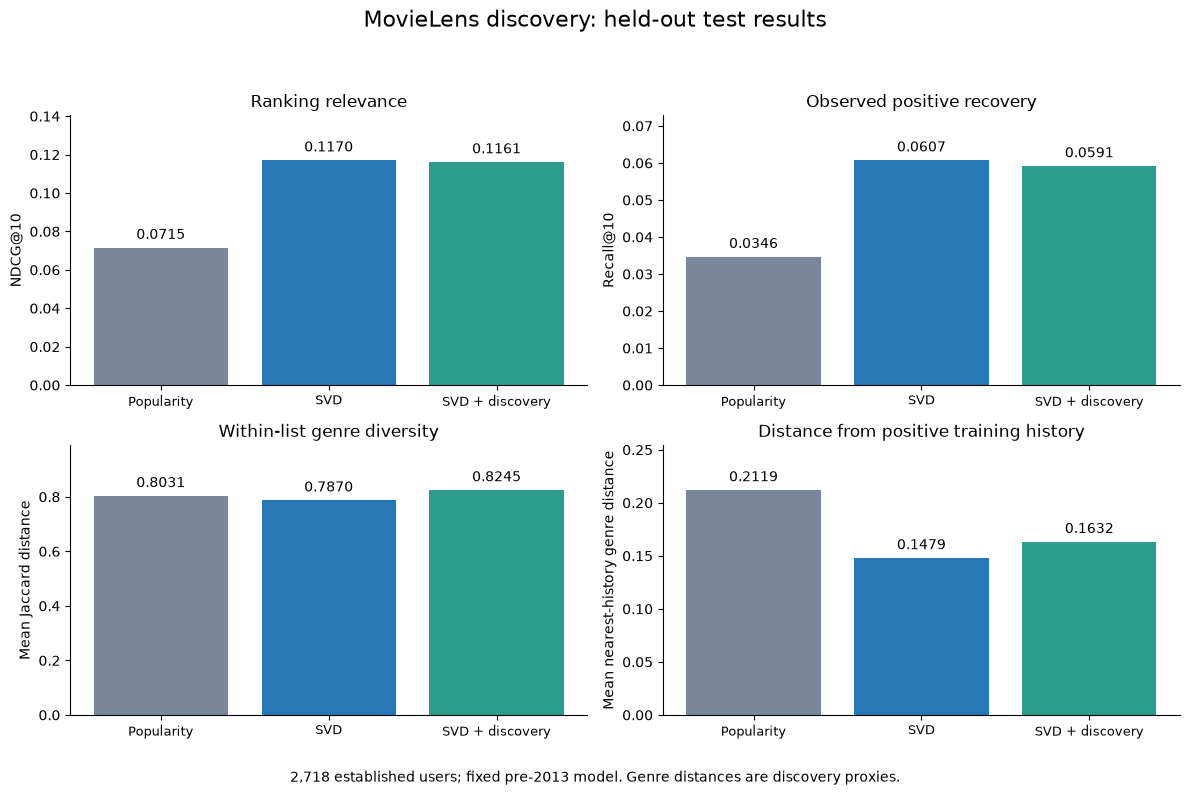

In [19]:
import matplotlib.pyplot as plt

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_order = [
    "Popularity",
    "SVD",
    "SVD + reranking (0.8)",
]
model_labels = ["Popularity", "SVD", "SVD + discovery"]
colors = ["#7A869A", "#2878B5", "#2A9D8F"]

plot_metrics = [
    ("ndcg@10", "Ranking relevance", "NDCG@10"),
    ("recall@10", "Observed positive recovery", "Recall@10"),
    ("genre_diversity", "Within-list genre diversity", "Mean Jaccard distance"),
    (
        "history_genre_distance",
        "Distance from positive training history",
        "Mean nearest-history genre distance",
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (metric, title, ylabel) in zip(
    axes.flat, plot_metrics
):
    values = test_summary.loc[model_order, metric].to_numpy()

    bars = ax.bar(model_labels, values, color=colors)
    ax.bar_label(bars, fmt="%.4f", padding=4)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(values) * 1.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=9)

fig.suptitle(
    "MovieLens discovery: held-out test results",
    fontsize=16,
)
fig.text(
    0.5,
    0.015,
    "2,718 established users; fixed pre-2013 model. "
    "Genre distances are discovery proxies.",
    ha="center",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0.05, 1, 0.94])

fig.savefig(
    FIGURES_DIR / "test_relevance_and_discovery.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Held-Out Results Interpretation

On 2,718 eligible test users, SVD improved Recall@10 by approximately 75.3% and NDCG@10 by 63.7% relative to the popularity baseline.

Discovery-aware reranking increased within-list genre diversity by approximately 4.8% and distance from positive training-history genre patterns by 10.3% relative to SVD. Both paired bootstrap intervals for these differences were above zero.

Reranking reduced Recall@10 by approximately 2.6% and NDCG@10 by 0.8%. Their paired bootstrap intervals included zero; this does not establish equivalence or prove the absence of a relevance cost.

Popularity novelty and catalog coverage did not improve with reranking. The supported discovery benefit is therefore greater genre variety and distance from historical preferences, rather than improvement across every discovery measure.

These results describe established users and movies present before 2013. Genre-based metrics do not establish that recommendations are unseen, surprising, or satisfying to viewers.

In [20]:
cohort_history = train_history_counts.reindex(test_user_ids)
median_history = cohort_history.median()

example_user_id = int(
    (cohort_history - median_history)
    .abs()
    .sort_index()
    .idxmin()
)

print(f"Example user: {example_user_id}")
print(f"Training ratings: {cohort_history.loc[example_user_id]:,}")

example_history = (
    train.loc[
        (train["userId"] == example_user_id)
        & (train["rating"] >= POSITIVE_THRESHOLD)
    ]
    .sort_values(["timestamp", "movieId"], ascending=[False, True])
    .head(10)
    .merge(
        movies,
        on="movieId",
        how="left",
        validate="many_to_one",
    )
)

print("\nMost recent positive training ratings")
display(
    example_history[["title", "genres", "rating", "timestamp"]]
)

example_tables = []

for name in ("SVD", "SVD + reranking (0.8)"):
    recommendations = test_results[name].loc[
        test_results[name]["userId"] == example_user_id,
        "recommendations",
    ].iloc[0]

    table = pd.DataFrame({
        "rank": range(1, len(recommendations) + 1),
        "movieId": recommendations,
    }).merge(
        movies,
        on="movieId",
        how="left",
        validate="one_to_one",
    )

    table["model"] = name
    example_tables.append(table)

example_recommendations = pd.concat(
    example_tables,
    ignore_index=True,
)

display(
    example_recommendations[
        ["model", "rank", "title", "genres"]
    ]
)

example_recommendations.to_csv(
    REPORTS_DIR / "example_recommendations.csv",
    index=False,
)

Example user: 6039
Training ratings: 399

Most recent positive training ratings


,title,genres,rating,timestamp
0,"Tillman Story, The (2010)",Documentary,4.5,2011-09-15 14:20:32
1,Sneakers (1992),Action|Comedy|Crime|Drama|Sci-Fi,5.0,2011-09-15 14:18:28
2,"O Brother, Where Art Thou? (2000)",Adventure|Comedy|Crime,4.0,2011-09-15 14:18:21
3,"Lock, Stock & Two Smoking Barrels (1998)",Comedy|Crime|Thriller,5.0,2011-09-15 14:18:08
4,"Fish Called Wanda, A (1988)",Comedy|Crime,5.0,2011-09-15 14:16:53
5,Out of Sight (1998),Comedy|Crime|Drama|Romance|Thriller,5.0,2011-08-20 21:53:56
6,Get Shorty (1995),Comedy|Crime|Thriller,5.0,2011-08-20 21:53:29
7,Broken Arrow (1996),Action|Adventure|Thriller,4.0,2011-08-20 21:53:20
8,"Birdcage, The (1996)",Comedy,4.5,2011-08-20 21:53:17
9,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,4.5,2011-08-20 21:53:05


,model,rank,title,genres
0,SVD,1,"Hunt for Red October, The (1990)",Action|Adventure|Thriller
1,SVD,2,Léon: The Professional (a.k.a. The Professiona...,Action|Crime|Drama|Thriller
2,SVD,3,"Sting, The (1973)",Comedy|Crime
3,SVD,4,"Departed, The (2006)",Crime|Drama|Thriller
4,SVD,5,"Untouchables, The (1987)",Action|Crime|Drama
5,SVD,6,"Dirty Dozen, The (1967)",Action|Drama|War
6,SVD,7,"Blues Brothers, The (1980)",Action|Comedy|Musical
7,SVD,8,Indiana Jones and the Temple of Doom (1984),Action|Adventure|Fantasy
8,SVD,9,"Prestige, The (2006)",Drama|Mystery|Sci-Fi|Thriller
9,SVD,10,Catch Me If You Can (2002),Crime|Drama


### Illustrative Recommendation Comparison

For a user selected by training-history length rather than test performance, reranking retained nine of the ten SVD recommendations. It replaced Catch Me If You Can with Finding Nemo, introducing Animation and Children's genres, and promoted The Dirty Dozen from sixth to fourth position.

This illustrates how the genre-similarity penalty changes a list while retaining most highly ranked candidates. It does not establish that the replacement is unfamiliar or preferable to the viewer. Overall effectiveness is assessed using the cohort-level metrics and uncertainty intervals reported above.

## Limitations, Potential Bias, and Responsible Use

### Selection and Activity Bias

MovieLens ratings reflect people who chose to use the service and rate particular movies. They do not represent all viewers or all
movies those viewers watched. Unrated items cannot be assumed to be disliked or unseen.

The primary cohort further favors established users: eligibility covers only 14.88% of test rating records before the positive-rating filter, and 2,019 of the 2,718 evaluated users have at least 200 training ratings. Results may therefore generalize poorly to infrequent users.

As a mitigation, performance is reported separately by training history length, and cohort coverage is disclosed. Users with 20–49 training ratings showed mixed results: SVD improved NDCG@10 but reduced Recall@10 relative to popularity. Cold-start evaluation and a separately tested fallback remain future work.

### Popularity and Representation

Frequently rated movies have more evidence available for learning, potentially limiting exposure for niche movies. Genre reranking increased genre diversity but did not improve popularity novelty or catalog coverage relative to SVD.

Reporting these separate metrics helps avoid claiming that genre diversity resolves popularity bias. A proposed improvement is to evaluate recommendation performance by item popularity as well as by user history length. Demographic fairness has not been assessed.

### Historical and Static Evaluation

Ratings end in March 2015, and the model and histories remain fixed at the pre-2013 cutoff. This does not represent current catalogs, streaming availability, or changing viewer preferences. A practical service would need current data and evaluation of periodic updates.

### Model and Measurement Limits

Binary interactions discard rating strength and combine lower ratings with missing interactions as zeros. Ordinary SVD approximates those zeros rather than treating them as entirely unknown.

Genre distances are coarse discovery proxies. Bootstrap intervals describe user-level variation conditional on the fitted models, not all sources of uncertainty. No user study establishes actual surprise, satisfaction, or improved viewing decisions.

### Responsible Deployment

Any future interface should distinguish model scores from probabilities and explain that recommendations are suggestions. Explicit preference feedback and user control over exploration are proposed safeguards; they have not been implemented or tested.

The research uses anonymized identifiers and does not attempt to identify participants. Commercial deployment would require appropriate permission under the dataset's usage terms.

## Summary

This project investigated whether personalized movie recommendations could support discovery beyond familiar choices using MovieLens 20M. A popularity baseline was compared with a 64-component TruncatedSVD model trained on positive ratings, followed by genre-aware reranking. On 2,718 eligible test users, SVD achieved Recall@10 of 0.0607 and NDCG@10 of 0.1170, improving on popularity by approximately 75.3% and 63.7%, respectively.

Reranking increased genre diversity by 4.8% and distance from positive training-history genre patterns by 10.3%, with positive paired bootstrap intervals for both differences.

Its observed relevance decreases were 2.6% in Recall@10 and 0.8% in NDCG@10, while popularity novelty and catalog coverage did not improve. The findings apply to established users and training-catalog movies in a historical, fixed-model evaluation, and discovery proxies require user validation before claims about surprise or satisfaction.